# Lab 10

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Questions

#### 1. Consider the following three variables for 20 different basketball players: points, assists, and rebounds. Perform k-means clustering manually with K=2, using Euclidean distance. Show the working for one iteration in your Lab Observation Book by using Euclidean distance. Write a Python function (without using the ```scikit-learn``` library) to create a DataFrame containing the three variables (points, assists, and rebounds) for 20 different basketball players. Apply the K-means algorithm to identify clusters with K=1, 2, K=3, and K=4, using distance formulas such as Euclidean distance, Manhattan distance, and Minkowski distance. Perform the following tasks:
- Create a scatter plot of the data points in blue.
- Plot the clusters with data points in different colors for K=1, 2, 3, and 4 in separate graphs.
- Create a plot showing the number of clusters on the x-axis and the Sum of Squared Errors (SSE) on the y-axis. Compute SSE for all iterations. Show the table of given data points against SSE for every iteration and use the total sum of SSE in the graph of K vs. SSE.
- Show the optimal value of K using the Elbow method and mark the same in the graph. 
- Redo the first four using Manhattan distance.
- Redo the first four using Minkowski distance.

In [2]:
data = {
    "points": [
        18.0, 19.0, 14.0, 14.0, 11.0, 20.0,
        28.0, 30.0, 31.0, 35.0, 33.0, 25.0,
        25.0, 27.0, 29.0, 30.0, 19.0, 23.0
    ],

    "assists": [
        3.0, 4.0, 5.0, 4.0, 7.0, 8.0,
        7.0, 6.0, 9.0, 12.0, 14.0, 9.0,
        4.0, 3.0, 4.0, 12.0, 15.0, 11.0
    ],

    "rebounds": [
        15, 14, 10, 8, 14, 13,
        9, 5, 4, 11, 6, 5,
        3, 8, 12, 7, 6, 5
    ]
}

df = pd.DataFrame(data)
df.index = range(1, len(df) + 1)
df.index.name = "player"
df.to_csv("rebounds.csv")

In [3]:
df = pd.read_csv("rebounds.csv")
df.head()

,player,points,assists,rebounds
0,1,18.0,3.0,15
1,2,19.0,4.0,14
2,3,14.0,5.0,10
3,4,14.0,4.0,8
4,5,11.0,7.0,14


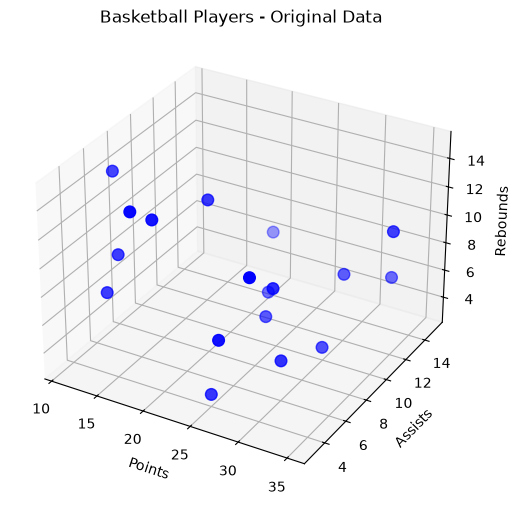

In [4]:
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    df["points"],
    df["assists"],
    df["rebounds"],
    c="blue",
    s=70
)

ax.set_xlabel("Points")
ax.set_ylabel("Assists")
ax.set_zlabel("Rebounds")
ax.set_title("Basketball Players - Original Data")

plt.show()

In [5]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan_distance(a, b):
    return np.sum(np.abs(a - b))

def minkowski_distance(a, b, p=3):
    return np.sum(np.abs(a - b) ** p) ** (1 / p)

In [6]:
X = df.values.astype(float)

c1 = X[0].copy()
c2 = X[9].copy()

print("Initial Centroid C1 =", c1)
print("Initial Centroid C2 =", c2)

manual_rows = []

for i, point in enumerate(X):
    d1 = euclidean_distance(point, c1)
    d2 = euclidean_distance(point, c2)

    if d1 <= d2:
        cluster = 1
    else:
        cluster = 2

    manual_rows.append([
        i + 1,
        point[0],
        point[1],
        point[2],
        d1,
        d2,
        cluster
    ])

manual_df = pd.DataFrame(
    manual_rows,
    columns=[
        "Player",
        "Points",
        "Assists",
        "Rebounds",
        "Distance from C1",
        "Distance from C2",
        "Cluster"
    ]
)

manual_df.head()

Initial Centroid C1 = [ 1. 18.  3. 15.]
Initial Centroid C2 = [10. 35. 12. 11.]


,Player,Points,Assists,Rebounds,Distance from C1,Distance from C2,Cluster
0,1,1.0,18.0,3.0,0.000000,21.610183,1
1,2,2.0,19.0,4.0,2.000000,19.824228,1
2,3,3.0,14.0,5.0,7.000000,23.237900,1
3,4,4.0,14.0,4.0,8.660254,23.452079,1
4,5,5.0,11.0,7.0,9.055385,25.199206,1


In [7]:
cluster1_points = X[manual_df["Cluster"].values == 1]
cluster2_points = X[manual_df["Cluster"].values == 2]

new_c1 = np.mean(cluster1_points, axis=0)
new_c2 = np.mean(cluster2_points, axis=0)

print(f"Old C1: {c1}")
print(f"New C1: {new_c1}\n")
print(f"Old C2: {c2}")
print(f"New C2: {new_c2}")

Old C1: [ 1. 18.  3. 15.]
New C1: [ 3.5        16.          5.16666667 12.33333333]

Old C2: [10. 35. 12. 11.]
New C2: [12.5        27.91666667  8.83333333  6.75      ]


In [8]:
def kmeans(
    X,
    k,
    distance="euclidean",
    p=3,
    iterations=100,
    random_state=67
):
    np.random.seed(random_state)
    X = np.array(X, dtype=float)

    indices = np.random.choice(len(X), k, replace=False)
    centroids = X[indices].copy()

    history = []

    for iteration in range(1, iterations + 1):
        labels = []
        distances_to_centroid = []

        for point in X:
            distances = []

            for centroid in centroids:
                if distance == "euclidean":
                    d = euclidean_distance(point, centroid)

                elif distance == "manhattan":
                    d = manhattan_distance(point, centroid)

                elif distance == "minkowski":
                    d = minkowski_distance(point, centroid, p)

                else:
                    raise ValueError("Invalid distance type")

                distances.append(d)

            cluster = np.argmin(distances)

            labels.append(cluster)
            distances_to_centroid.append(distances[cluster])

        labels = np.array(labels)

        for i in range(len(X)):
            history.append({
                "Iteration": iteration,
                "Player": i + 1,
                "Points": X[i][0],
                "Assists": X[i][1],
                "Rebounds": X[i][2],
                "Cluster": labels[i] + 1,
                "Distance": distances_to_centroid[i],
                "Squared Error": distances_to_centroid[i] ** 2
            })

        new_centroids = []

        for cluster_id in range(k):
            cluster_points = X[labels == cluster_id]

            if len(cluster_points) == 0:
                new_centroids.append(centroids[cluster_id])

            else:
                new_centroids.append(np.mean(cluster_points, axis=0))

        new_centroids = np.array(new_centroids)

        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    history_df = pd.DataFrame(history)
    last_iteration = history_df["Iteration"].max()

    final_sse = history_df[
        history_df["Iteration"] == last_iteration
    ]["Squared Error"].sum()

    return labels, centroids, final_sse, history_df

In [9]:
def plot_clusters(X, labels, centroids, k, distance):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    colors = ["red", "green", "blue", "orange"]

    for cluster_id in range(k):
        cluster_points = X[labels == cluster_id]

        ax.scatter(
            cluster_points[:, 0],
            cluster_points[:, 1],
            cluster_points[:, 2],
            s=70,
            color=colors[cluster_id],
            label=f"Cluster {cluster_id + 1}"
        )

    ax.scatter(
        centroids[:, 0],
        centroids[:, 1],
        centroids[:, 2],
        color="black",
        marker="X",
        s=250,
        label="Centroids"
    )

    ax.set_xlabel("Points")
    ax.set_ylabel("Assists")
    ax.set_zlabel("Rebounds")

    ax.set_title(f"K-Means using {distance} Distance - K={k}")

    ax.legend()
    plt.show()

In [10]:
def show_sse_tables(history_df):
    print("POINT-WISE SSE FOR EVERY ITERATION")
    
    display(
        history_df[
            [
                "Iteration",
                "Player",
                "Points",
                "Assists",
                "Rebounds",
                "Cluster",
                "Distance",
                "Squared Error"
            ]
        ]
    )

    print("\nTOTAL SSE FOR EVERY ITERATION")

    iteration_sse = (
        history_df
        .groupby("Iteration")["Squared Error"]
        .sum()
        .reset_index()
    )

    iteration_sse.columns = ["Iteration", "Total SSE"]
    display(iteration_sse)

    return iteration_sse

K = 1

Final Centroids:
[[ 9.5        23.94444444  7.61111111  8.61111111]]

Final SSE = 1832.0


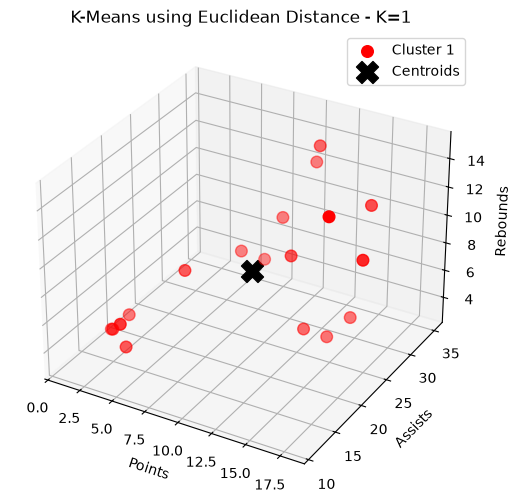

K = 2

Final Centroids:
[[ 3.5        16.          5.16666667 12.33333333]
 [12.5        27.91666667  8.83333333  6.75      ]]

Final SSE = 761.4999999999999


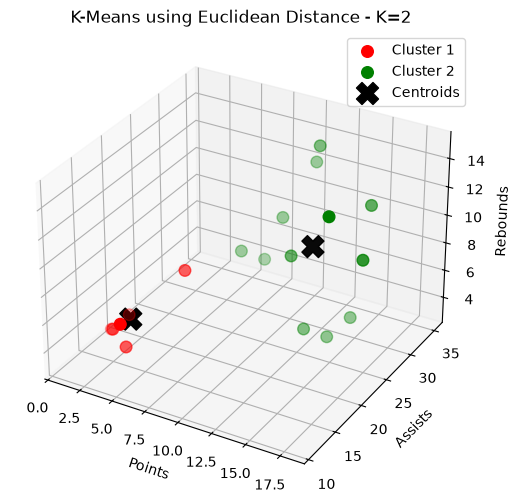

K = 3

Final Centroids:
[[ 3.         19.          5.         14.        ]
 [12.5        27.91666667  8.83333333  6.75      ]
 [ 4.         13.          5.33333333 10.66666667]]

Final SSE = 689.1666666666666


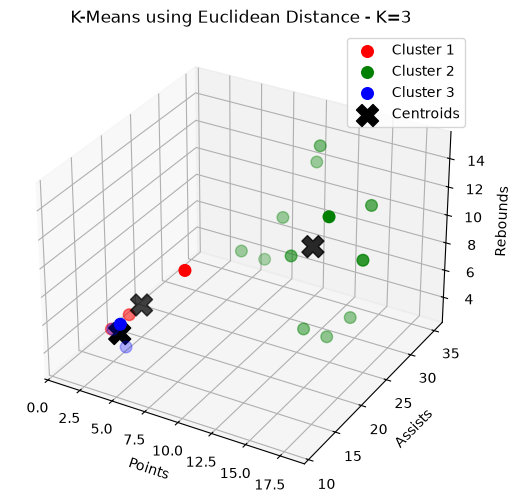

K = 4

Final Centroids:
[[ 3.         19.          5.         14.        ]
 [12.5        27.91666667  8.83333333  6.75      ]
 [ 5.         11.          7.         14.        ]
 [ 3.5        14.          4.5         9.        ]]

Final SSE = 660.8333333333333


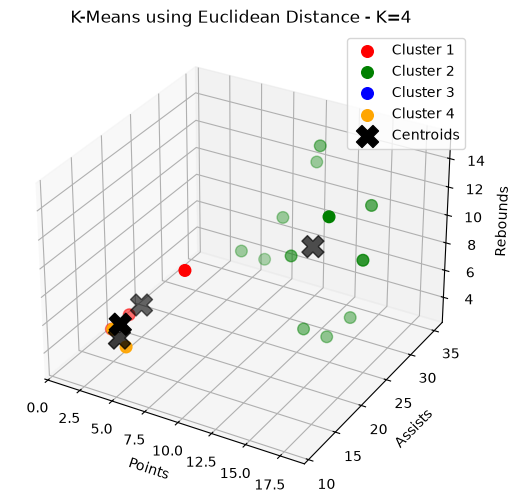

In [11]:
X = df.values.astype(float)

euclidean_results = {}
euclidean_sse = []

for k in range(1, 5):
    labels, centroids, sse, history = kmeans(
        X,
        k=k,
        distance="euclidean"
    )

    euclidean_results[k] = {
        "labels": labels,
        "centroids": centroids,
        "sse": sse,
        "history": history
    }

    euclidean_sse.append(sse)

    print("=" * 60)
    print(f"K = {k}")
    print("=" * 60)

    print("\nFinal Centroids:")
    print(centroids)

    print("\nFinal SSE =", sse)

    plot_clusters(
        X,
        labels,
        centroids,
        k,
        "Euclidean"
    )

In [12]:
for k in range(1, 5):
    print("\n")
    print("=" * 70)
    print(f"MINKOWSKI DISTANCE : K = {k}")
    print("=" * 70)

    show_sse_tables(euclidean_results[k]["history"])



MINKOWSKI DISTANCE : K = 1
POINT-WISE SSE FOR EVERY ITERATION


,Iteration,Player,Points,Assists,Rebounds,Cluster,Distance,Squared Error
0,1,1,1.0,18.0,3.0,1,2.000000,4.000000
1,1,2,2.0,19.0,4.0,1,0.000000,0.000000
2,1,3,3.0,14.0,5.0,1,6.557439,43.000000
3,1,4,4.0,14.0,4.0,1,8.062258,65.000000
4,1,5,5.0,11.0,7.0,1,9.055385,82.000000
5,1,6,6.0,20.0,8.0,1,5.830952,34.000000
6,1,7,7.0,28.0,7.0,1,11.832160,140.000000
7,1,8,8.0,30.0,6.0,1,15.556349,242.000000
8,1,9,9.0,31.0,9.0,1,17.832555,318.000000
9,1,10,10.0,35.0,12.0,1,19.824228,393.000000



TOTAL SSE FOR EVERY ITERATION


,Iteration,Total SSE
0,1,4042.0
1,2,1832.0




MINKOWSKI DISTANCE : K = 2
POINT-WISE SSE FOR EVERY ITERATION


...

,Iteration,Total SSE
0,1,1306.000000
1,2,689.166667




MINKOWSKI DISTANCE : K = 4
POINT-WISE SSE FOR EVERY ITERATION


,Iteration,Player,Points,Assists,Rebounds,Cluster,Distance,Squared Error
0,1,1,1.0,18.0,3.0,1,2.000000,4.000000
1,1,2,2.0,19.0,4.0,1,0.000000,0.000000
2,1,3,3.0,14.0,5.0,4,0.000000,0.000000
3,1,4,4.0,14.0,4.0,4,2.449490,6.000000
4,1,5,5.0,11.0,7.0,3,0.000000,0.000000
5,1,6,6.0,20.0,8.0,1,5.830952,34.000000
6,1,7,7.0,28.0,7.0,2,9.486833,90.000000
7,1,8,8.0,30.0,6.0,2,7.615773,58.000000
8,1,9,9.0,31.0,9.0,2,8.831761,78.000000
9,1,10,10.0,35.0,12.0,2,15.394804,237.000000



TOTAL SSE FOR EVERY ITERATION


,Iteration,Total SSE
0,1,1224.000000
1,2,660.833333


In [13]:
def find_elbow(k_values, sse_values):

    x = np.array(k_values, dtype=float)
    y = np.array(sse_values, dtype=float)

    # Normalize values
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())

    first = np.array([x_norm[0], y_norm[0]])
    last = np.array([x_norm[-1], y_norm[-1]])

    line = last - first
    line_length = np.linalg.norm(line)

    distances = []

    for i in range(len(x)):

        point = np.array([
            x_norm[i],
            y_norm[i]
        ])

        # Perpendicular distance from point to line
        distance = abs(
            line[0] * (point[1] - first[1])
            - line[1] * (point[0] - first[0])
        ) / line_length

        distances.append(distance)

    elbow_index = np.argmax(distances)

    return k_values[elbow_index]

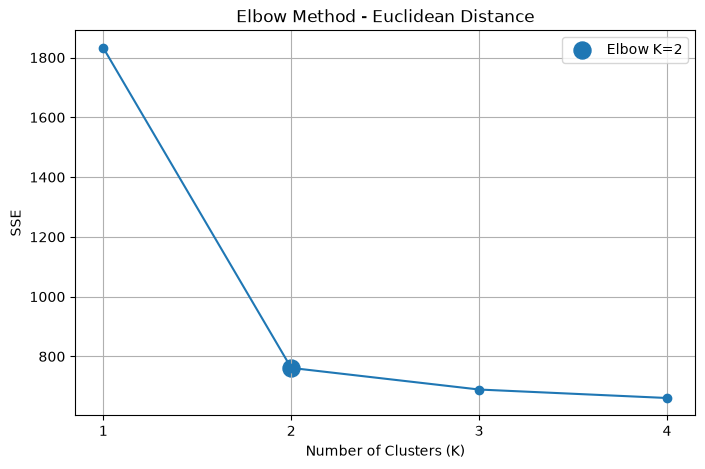

Optimal K = 2


In [14]:
k_values = [1, 2, 3, 4]

optimal_k_euclidean = find_elbow(
    k_values,
    euclidean_sse
)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    euclidean_sse,
    marker="o"
)

optimal_index = k_values.index(optimal_k_euclidean)

plt.scatter(
    optimal_k_euclidean,
    euclidean_sse[optimal_index],
    s=150,
    label=f"Elbow K={optimal_k_euclidean}"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE")
plt.title("Elbow Method - Euclidean Distance")

plt.xticks(k_values)
plt.grid()
plt.legend()

plt.show()

print(f"Optimal K = {optimal_k_euclidean}")

In [15]:
euclidean_sse_table = pd.DataFrame({
    "K": k_values,
    "SSE": euclidean_sse
})

euclidean_sse_table

,K,SSE
0,1,1832.000000
1,2,761.500000
2,3,689.166667
3,4,660.833333


K = 1

Final Centroids:
[[ 9.5        23.94444444  7.61111111  8.61111111]]

Final SSE = 5586.6790123456785


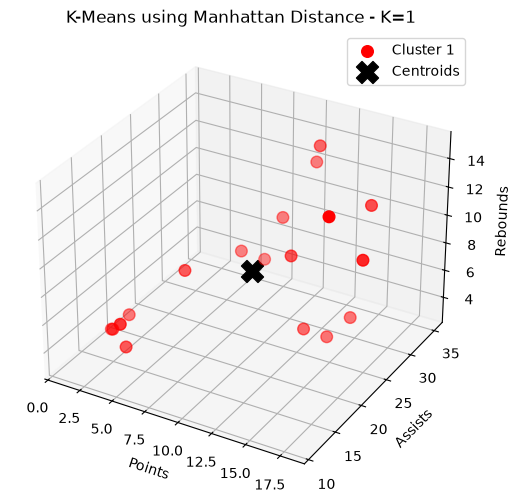

K = 2

Final Centroids:
[[ 3.5        16.          5.16666667 12.33333333]
 [12.5        27.91666667  8.83333333  6.75      ]]

Final SSE = 2332.8888888888887


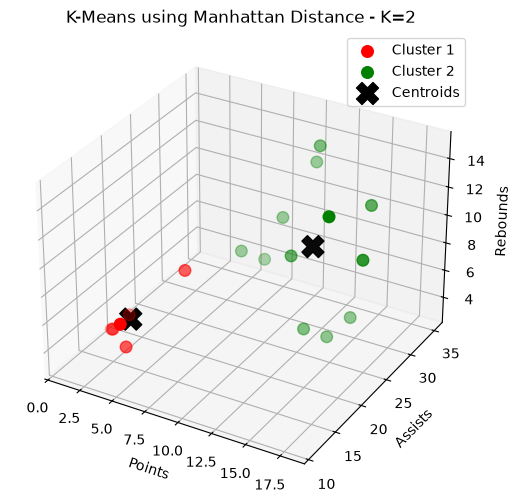

K = 3

Final Centroids:
[[ 3.2        17.          4.8        12.        ]
 [12.5        27.91666667  8.83333333  6.75      ]
 [ 5.         11.          7.         14.        ]]

Final SSE = 2206.12


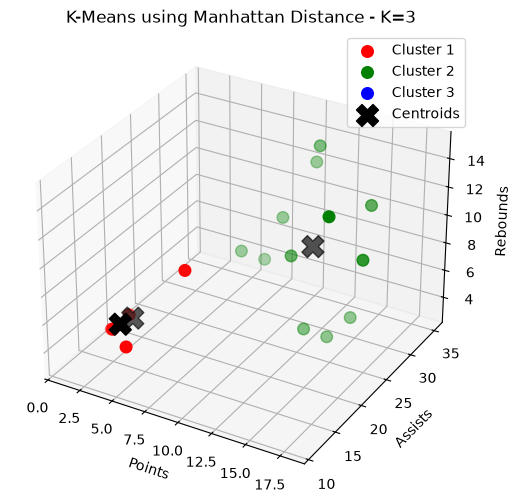

K = 4

Final Centroids:
[[ 3.         19.          5.         14.        ]
 [12.5        27.91666667  8.83333333  6.75      ]
 [ 5.         11.          7.         14.        ]
 [ 3.5        14.          4.5         9.        ]]

Final SSE = 2015.0


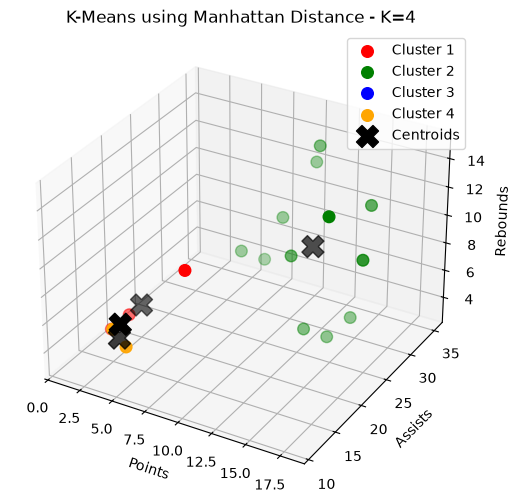

In [16]:
manhattan_results = {}
manhattan_sse = []

for k in range(1, 5):
    labels, centroids, sse, history = kmeans(
        X,
        k=k,
        distance="manhattan"
    )

    manhattan_results[k] = {
        "labels": labels,
        "centroids": centroids,
        "sse": sse,
        "history": history
    }

    manhattan_sse.append(sse)

    print("=" * 60)
    print(f"K = {k}")
    print("=" * 60)

    print("\nFinal Centroids:")
    print(centroids)

    print("\nFinal SSE =", sse)

    plot_clusters(
        X,
        labels,
        centroids,
        k,
        "Manhattan"
    )

In [17]:
for k in range(1, 5):
    print("\n")
    print("=" * 70)
    print(f"MANHATTAN DISTANCE : K = {k}")
    print("=" * 70)

    show_sse_tables(manhattan_results[k]["history"])



MANHATTAN DISTANCE : K = 1
POINT-WISE SSE FOR EVERY ITERATION


,Iteration,Player,Points,Assists,Rebounds,Cluster,Distance,Squared Error
0,1,1,1.0,18.0,3.0,1,4.000000,16.000000
1,1,2,2.0,19.0,4.0,1,0.000000,0.000000
2,1,3,3.0,14.0,5.0,1,11.000000,121.000000
3,1,4,4.0,14.0,4.0,1,13.000000,169.000000
4,1,5,5.0,11.0,7.0,1,14.000000,196.000000
5,1,6,6.0,20.0,8.0,1,10.000000,100.000000
6,1,7,7.0,28.0,7.0,1,22.000000,484.000000
7,1,8,8.0,30.0,6.0,1,28.000000,784.000000
8,1,9,9.0,31.0,9.0,1,34.000000,1156.000000
9,1,10,10.0,35.0,12.0,1,35.000000,1225.000000



TOTAL SSE FOR EVERY ITERATION


,Iteration,Total SSE
0,1,13022.000000
1,2,5586.679012




MANHATTAN DISTANCE : K = 2
POINT-WISE SSE FOR EVERY ITERATION


...

,Iteration,Total SSE
0,1,4154.00
1,2,2206.12




MANHATTAN DISTANCE : K = 4
POINT-WISE SSE FOR EVERY ITERATION


,Iteration,Player,Points,Assists,Rebounds,Cluster,Distance,Squared Error
0,1,1,1.0,18.0,3.0,1,4.000000,16.000000
1,1,2,2.0,19.0,4.0,1,0.000000,0.000000
2,1,3,3.0,14.0,5.0,4,0.000000,0.000000
3,1,4,4.0,14.0,4.0,4,4.000000,16.000000
4,1,5,5.0,11.0,7.0,3,0.000000,0.000000
5,1,6,6.0,20.0,8.0,1,10.000000,100.000000
6,1,7,7.0,28.0,7.0,2,18.000000,324.000000
7,1,8,8.0,30.0,6.0,2,14.000000,196.000000
8,1,9,9.0,31.0,9.0,2,16.000000,256.000000
9,1,10,10.0,35.0,12.0,2,29.000000,841.000000



TOTAL SSE FOR EVERY ITERATION


,Iteration,Total SSE
0,1,3880.0
1,2,2015.0


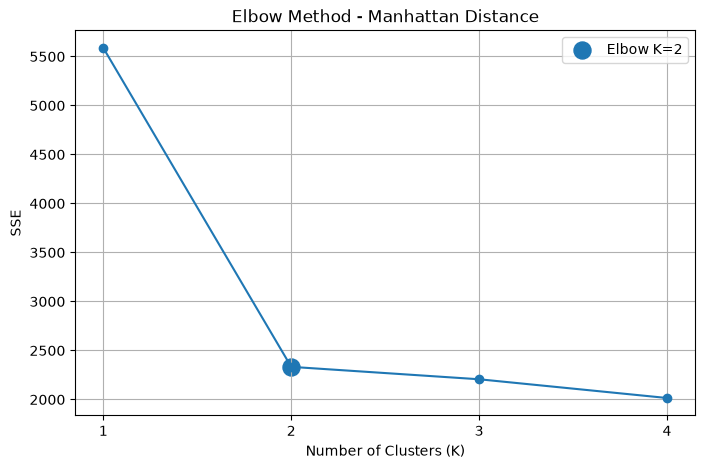

Optimal K = 2


In [18]:
optimal_k_manhattan = find_elbow(
    k_values,
    manhattan_sse
)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    manhattan_sse,
    marker="o"
)

optimal_index = k_values.index(optimal_k_manhattan)

plt.scatter(
    optimal_k_manhattan,
    manhattan_sse[optimal_index],
    s=150,
    label=f"Elbow K={optimal_k_manhattan}"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE")
plt.title("Elbow Method - Manhattan Distance")

plt.xticks(k_values)
plt.grid()
plt.legend()

plt.show()

print(f"Optimal K = {optimal_k_manhattan}")

In [19]:
manhattan_sse_table = pd.DataFrame({
    "K": k_values,
    "SSE": manhattan_sse
})

manhattan_sse_table

,K,SSE
0,1,5586.679012
1,2,2332.888889
2,3,2206.120000
3,4,2015.000000


K = 1

Final Centroids:
[[ 9.5        23.94444444  7.61111111  8.61111111]]

Final SSE = 1381.001897554609


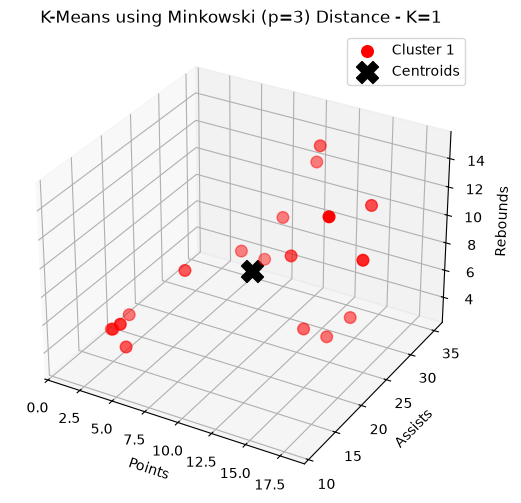

K = 2

Final Centroids:
[[ 3.5        16.          5.16666667 12.33333333]
 [12.5        27.91666667  8.83333333  6.75      ]]

Final SSE = 569.4804205084345


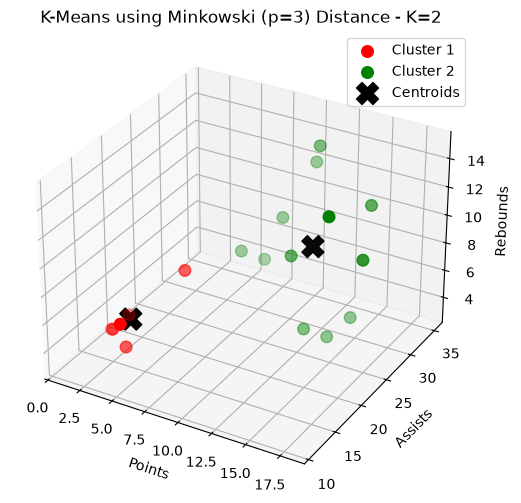

K = 3

Final Centroids:
[[ 3.         19.          5.         14.        ]
 [12.5        27.91666667  8.83333333  6.75      ]
 [ 4.         13.          5.33333333 10.66666667]]

Final SSE = 514.2708345550344


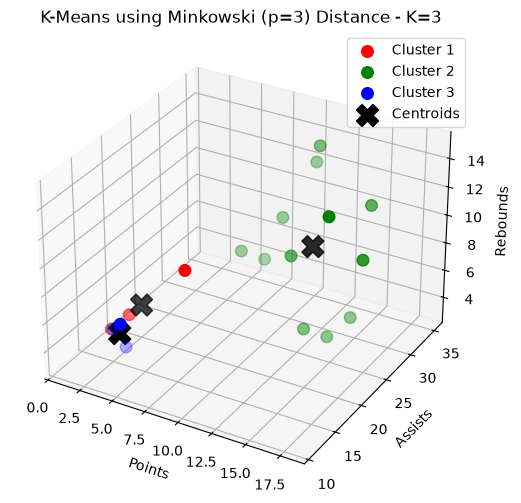

K = 4

Final Centroids:
[[ 3.         19.          5.         14.        ]
 [12.5        27.91666667  8.83333333  6.75      ]
 [ 5.         11.          7.         14.        ]
 [ 3.5        14.          4.5         9.        ]]

Final SSE = 493.20942313048937


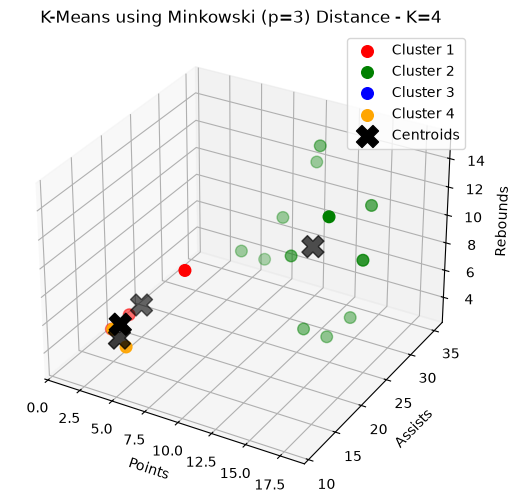

In [20]:
minkowski_results = {}
minkowski_sse = []

for k in range(1, 5):
    labels, centroids, sse, history = kmeans(
        X,
        k=k,
        distance="minkowski",
        p=3
    )

    minkowski_results[k] = {
        "labels": labels,
        "centroids": centroids,
        "sse": sse,
        "history": history
    }

    minkowski_sse.append(sse)

    print("=" * 60)
    print(f"K = {k}")
    print("=" * 60)

    print("\nFinal Centroids:")
    print(centroids)

    print("\nFinal SSE =", sse)

    plot_clusters(
        X,
        labels,
        centroids,
        k,
        "Minkowski (p=3)"
    )

In [21]:
for k in range(1, 5):
    print("\n")
    print("=" * 70)
    print(f"MINKOWSKI DISTANCE : K = {k}")
    print("=" * 70)

    show_sse_tables(minkowski_results[k]["history"])



MINKOWSKI DISTANCE : K = 1
POINT-WISE SSE FOR EVERY ITERATION


,Iteration,Player,Points,Assists,Rebounds,Cluster,Distance,Squared Error
0,1,1,1.0,18.0,3.0,1,1.587401,2.519842
1,1,2,2.0,19.0,4.0,1,0.000000,0.000000
2,1,3,3.0,14.0,5.0,1,5.758965,33.165680
3,1,4,4.0,14.0,4.0,1,7.040581,49.569775
4,1,5,5.0,11.0,7.0,1,8.271904,68.424393
5,1,6,6.0,20.0,8.0,1,5.065797,25.662299
6,1,7,7.0,28.0,7.0,1,10.019960,100.399601
7,1,8,8.0,30.0,6.0,1,13.169381,173.432599
8,1,9,9.0,31.0,9.0,1,14.729983,216.972410
9,1,10,10.0,35.0,12.0,1,17.265721,298.105127



TOTAL SSE FOR EVERY ITERATION


,Iteration,Total SSE
0,1,2916.168932
1,2,1381.001898




MINKOWSKI DISTANCE : K = 2
POINT-WISE SSE FOR EVERY ITERATION


...

,Iteration,Total SSE
0,1,966.068300
1,2,514.270835




MINKOWSKI DISTANCE : K = 4
POINT-WISE SSE FOR EVERY ITERATION


,Iteration,Player,Points,Assists,Rebounds,Cluster,Distance,Squared Error
0,1,1,1.0,18.0,3.0,1,1.587401,2.519842
1,1,2,2.0,19.0,4.0,1,0.000000,0.000000
2,1,3,3.0,14.0,5.0,4,0.000000,0.000000
3,1,4,4.0,14.0,4.0,4,2.154435,4.641589
4,1,5,5.0,11.0,7.0,3,0.000000,0.000000
5,1,6,6.0,20.0,8.0,1,5.065797,25.662299
6,1,7,7.0,28.0,7.0,2,7.862224,61.814569
7,1,8,8.0,30.0,6.0,2,6.431228,41.360688
8,1,9,9.0,31.0,9.0,2,7.404721,54.829888
9,1,10,10.0,35.0,12.0,2,12.705406,161.427346



TOTAL SSE FOR EVERY ITERATION


,Iteration,Total SSE
0,1,906.294135
1,2,493.209423


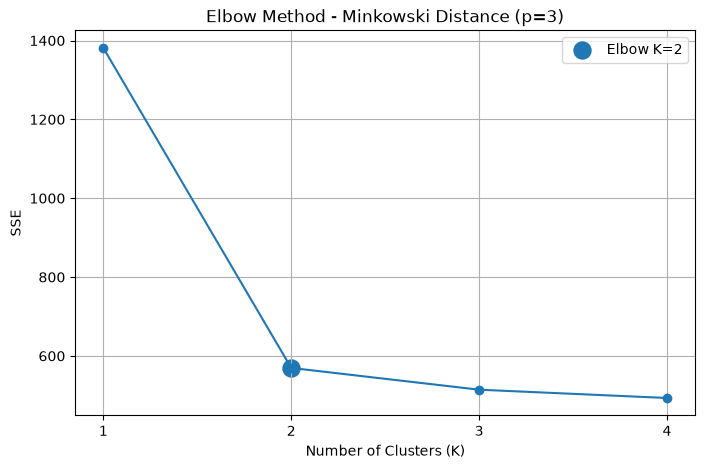

Optimal K = 2


In [22]:
optimal_k_minkowski = find_elbow(
    k_values,
    minkowski_sse
)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    minkowski_sse,
    marker="o"
)

optimal_index = k_values.index(optimal_k_minkowski)

plt.scatter(
    optimal_k_minkowski,
    minkowski_sse[optimal_index],
    s=150,
    label=f"Elbow K={optimal_k_minkowski}"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE")
plt.title(
    f"Elbow Method - Minkowski Distance (p=3)"
)

plt.xticks(k_values)
plt.grid()
plt.legend()

plt.show()

print(f"Optimal K = {optimal_k_minkowski}")

In [23]:
minkowski_sse_table = pd.DataFrame({
    "K": k_values,
    "SSE": minkowski_sse
})

minkowski_sse_table

,K,SSE
0,1,1381.001898
1,2,569.480421
2,3,514.270835
3,4,493.209423


In [24]:
comparison = pd.DataFrame({
    "K": k_values,
    "Euclidean SSE": euclidean_sse,
    "Manhattan SSE": manhattan_sse,
    "Minkowski SSE": minkowski_sse
})

comparison

,K,Euclidean SSE,Manhattan SSE,Minkowski SSE
0,1,1832.000000,5586.679012,1381.001898
1,2,761.500000,2332.888889,569.480421
2,3,689.166667,2206.120000,514.270835
3,4,660.833333,2015.000000,493.209423


In [25]:
optimal_comparison = pd.DataFrame({
    "Distance": [
        "Euclidean",
        "Manhattan",
        f"Minkowski (p=3)"
    ],

    "Optimal K": [
        optimal_k_euclidean,
        optimal_k_manhattan,
        optimal_k_minkowski
    ]
})

optimal_comparison

,Distance,Optimal K
0,Euclidean,2
1,Manhattan,2
2,Minkowski (p=3),2


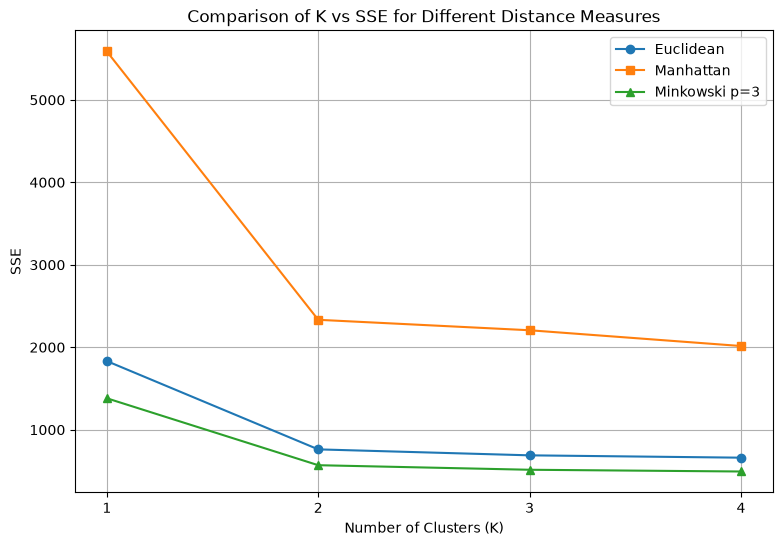

In [26]:
plt.figure(figsize=(9, 6))

plt.plot(
    k_values,
    euclidean_sse,
    marker="o",
    label="Euclidean"
)

plt.plot(
    k_values,
    manhattan_sse,
    marker="s",
    label="Manhattan"
)

plt.plot(
    k_values,
    minkowski_sse,
    marker="^",
    label=f"Minkowski p=3"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE")

plt.title(
    "Comparison of K vs SSE for Different Distance Measures"
)

plt.xticks(k_values)
plt.grid()
plt.legend()

plt.show()

In [27]:
best_result = euclidean_results[optimal_k_euclidean]

final_df = df.copy()

final_df["Cluster"] = (
    best_result["labels"] + 1
)

final_df

,player,points,assists,rebounds,Cluster
0,1,18.0,3.0,15,1
1,2,19.0,4.0,14,1
2,3,14.0,5.0,10,1
3,4,14.0,4.0,8,1
4,5,11.0,7.0,14,1
5,6,20.0,8.0,13,1
6,7,28.0,7.0,9,2
7,8,30.0,6.0,5,2
8,9,31.0,9.0,4,2
9,10,35.0,12.0,11,2


#### 2. For the following 1-dimensional data points apply agglomerative hierarchical clustering to build the dendrogram. Construct the proximity matrix (distance matrix). Merge the clusters using the single linkage (min distance) and update the proximity matrix accordingly. Clearly show the proximity matrix corresponding to each iteration of the algorithm. 

`18, 22, 25, 27, 42, 43`

In [28]:
data = [18, 22, 25, 27, 42, 43]
data

[18, 22, 25, 27, 42, 43]

In [29]:
def distance(a, b):
    return abs(a - b)

In [30]:
def create_distance_matrix(clusters):
    n = len(clusters)
    matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            if i == j:
                matrix[i][j] = 0
            
            else:
                distances = []
                
                for x in clusters[i]:
                    for y in clusters[j]:
                        distances.append(distance(x, y))
                
                matrix[i][j] = min(distances)
    
    return matrix

In [31]:
clusters = [[x] for x in data]
clusters

[[18], [22], [25], [27], [42], [43]]

In [32]:
matrix = create_distance_matrix(clusters)

labels = [str(cluster) for cluster in clusters]

distance_df = pd.DataFrame(
    matrix,
    index=labels,
    columns=labels
)

distance_df

,[18],[22],[25],[27],[42],[43]
[18],0.0,4.0,7.0,9.0,24.0,25.0
[22],4.0,0.0,3.0,5.0,20.0,21.0
[25],7.0,3.0,0.0,2.0,17.0,18.0
[27],9.0,5.0,2.0,0.0,15.0,16.0
[42],24.0,20.0,17.0,15.0,0.0,1.0
[43],25.0,21.0,18.0,16.0,1.0,0.0


In [33]:
def find_closest_clusters(matrix):
    min_distance = float("inf")
    min_i = -1
    min_j = -1
    
    for i in range(len(matrix)):
        for j in range(i + 1, len(matrix)):
            if matrix[i][j] < min_distance:
                min_distance = matrix[i][j]
                min_i = i
                min_j = j
    
    return min_i, min_j, min_distance

In [34]:
clusters = [[x] for x in data]
iteration = 0
merge_history = []

while len(clusters) > 1:
    print("=" * 70)
    print(f"ITERATION {iteration}")
    print("=" * 70)
    
    print("\nClusters:")
    print(clusters)
    
    matrix = create_distance_matrix(clusters)    
    labels = [str(cluster) for cluster in clusters]
    
    df_matrix = pd.DataFrame(
        matrix,
        index=labels,
        columns=labels
    )
    
    print("\nProximity Matrix:")
    display(df_matrix)
    
    i, j, min_distance = find_closest_clusters(matrix)
    
    print(f"\nMinimum Distance = {min_distance}")
    print(f"Merging {clusters[i]} and {clusters[j]}")
    
    merge_history.append({
        "Iteration": iteration + 1,
        "Cluster 1": clusters[i].copy(),
        "Cluster 2": clusters[j].copy(),
        "Distance": min_distance
    })
    
    new_cluster = clusters[i] + clusters[j]    
    new_clusters = []
    
    for idx, cluster in enumerate(clusters):
        if idx != i and idx != j:
            new_clusters.append(cluster)
    
    new_clusters.append(new_cluster)
    new_clusters.sort(key=lambda x: min(x))
    
    clusters = new_clusters
    
    iteration += 1

ITERATION 0

Clusters:
[[18], [22], [25], [27], [42], [43]]

Proximity Matrix:


,[18],[22],[25],[27],[42],[43]
[18],0.0,4.0,7.0,9.0,24.0,25.0
[22],4.0,0.0,3.0,5.0,20.0,21.0
[25],7.0,3.0,0.0,2.0,17.0,18.0
[27],9.0,5.0,2.0,0.0,15.0,16.0
[42],24.0,20.0,17.0,15.0,0.0,1.0
[43],25.0,21.0,18.0,16.0,1.0,0.0



Minimum Distance = 1.0
Merging [42] and [43]
ITERATION 1

Clusters:
[[18], [22], [25], [27], [42, 43]]

Proximity Matrix:


,[18],[22],[25],[27],"[42, 43]"
[18],0.0,4.0,7.0,9.0,24.0
[22],4.0,0.0,3.0,5.0,20.0
[25],7.0,3.0,0.0,2.0,17.0
[27],9.0,5.0,2.0,0.0,15.0
"[42, 43]",24.0,20.0,17.0,15.0,0.0



Minimum Distance = 2.0
Merging [25] and [27]
ITERATION 2

Clusters:
[[18], [22], [25, 27], [42, 43]]

Proximity Matrix:


...


Minimum Distance = 3.0
Merging [22] and [25, 27]
ITERATION 3

Clusters:
[[18], [22, 25, 27], [42, 43]]

Proximity Matrix:


,[18],"[22, 25, 27]","[42, 43]"
[18],0.0,4.0,24.0
"[22, 25, 27]",4.0,0.0,15.0
"[42, 43]",24.0,15.0,0.0



Minimum Distance = 4.0
Merging [18] and [22, 25, 27]
ITERATION 4

Clusters:
[[18, 22, 25, 27], [42, 43]]

Proximity Matrix:


,"[18, 22, 25, 27]","[42, 43]"
"[18, 22, 25, 27]",0.0,15.0
"[42, 43]",15.0,0.0



Minimum Distance = 15.0
Merging [18, 22, 25, 27] and [42, 43]


In [35]:
merge_df = pd.DataFrame(merge_history)
merge_df

,Iteration,Cluster 1,Cluster 2,Distance
0,1,[42],[43],1.0
1,2,[25],[27],2.0
2,3,[22],"[25, 27]",3.0
3,4,[18],"[22, 25, 27]",4.0
4,5,"[18, 22, 25, 27]","[42, 43]",15.0


In [36]:
from scipy.cluster.hierarchy import linkage, dendrogram

X = np.array(data).reshape(-1, 1)

Z = linkage(
    X,
    method="single",
    metric="euclidean"
)

Z

array([[ 4.,  5.,  1.,  2.],
       [ 2.,  3.,  2.,  2.],
       [ 1.,  7.,  3.,  3.],
       [ 0.,  8.,  4.,  4.],
       [ 6.,  9., 15.,  6.]])

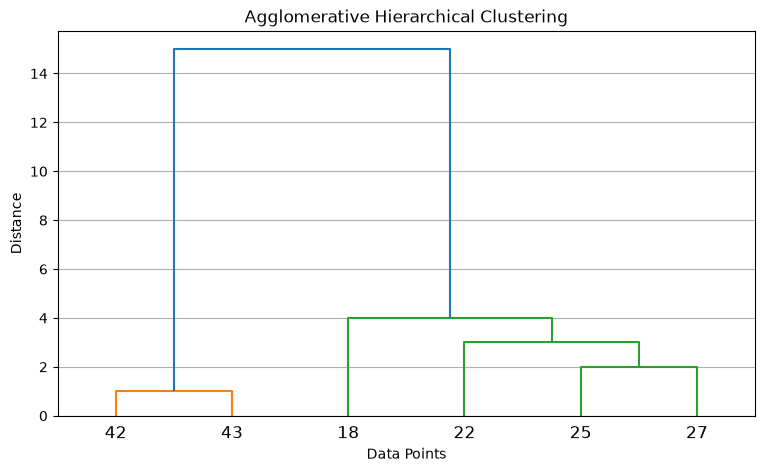

In [37]:
plt.figure(figsize=(9, 5))

dendrogram(
    Z,
    labels=[str(x) for x in data]
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.grid(axis="y")

plt.show()

#### 3. Consider the following data set and apply the hierarchical data-clustering algorithm, to identify the clusters. Solve it manually by considering all linkage functions (Single, Complete and Average) using Euclidean distance.

In [38]:
data = {
    "Point": ["p1", "p2", "p3", "p4", "p5", "p6", "p7", "p8", "p9"],
    "x": [1, 3, 9, 3, 7, 9, 4, 8, 1],
    "y": [1, 2, 1, 7, 2, 7, 8, 3, 4]
}

df = pd.DataFrame(data)
df.to_csv("hierarchical.csv", index=False)

In [39]:
df = pd.read_csv("hierarchical.csv")
df.head()

,Point,x,y
0,p1,1,1
1,p2,3,2
2,p3,9,1
3,p4,3,7
4,p5,7,2


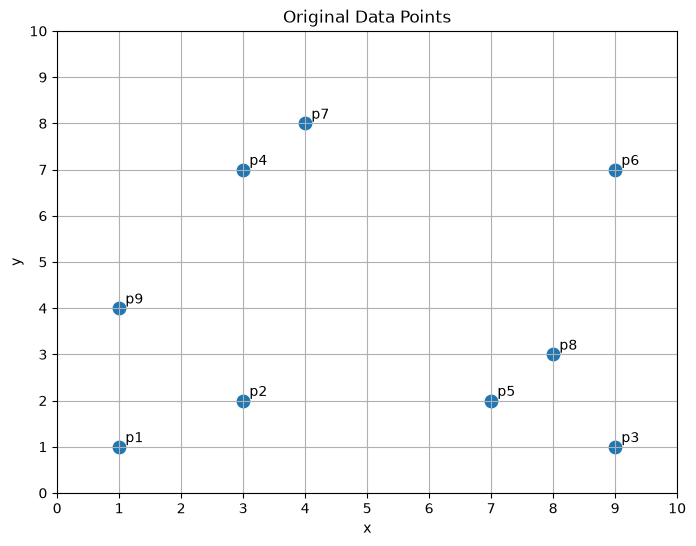

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["x"],
    df["y"],
    s=80
)

for i in range(len(df)):
    plt.text(
        df.loc[i, "x"] + 0.1,
        df.loc[i, "y"] + 0.1,
        df.loc[i, "Point"]
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Original Data Points")

plt.xticks(range(0, 11))
plt.yticks(range(0, 11))

plt.grid()

plt.show()

In [41]:
def euclidean_distance(a, b):
    return np.sqrt(
        (a[0] - b[0])**2 +
        (a[1] - b[1])**2
    )

In [42]:
points = df[["x", "y"]].values
labels = df["Point"].tolist()

n = len(points)

distance_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        distance_matrix[i, j] = euclidean_distance(
            points[i],
            points[j]
        )

distance_df = pd.DataFrame(
    distance_matrix,
    index=labels,
    columns=labels
)

distance_df.round(3)

,p1,p2,p3,p4,p5,p6,p7,p8,p9
p1,0.000,2.236,8.000,6.325,6.083,10.000,7.616,7.280,3.000
p2,2.236,0.000,6.083,5.000,4.000,7.810,6.083,5.099,2.828
p3,8.000,6.083,0.000,8.485,2.236,6.000,8.602,2.236,8.544
p4,6.325,5.000,8.485,0.000,6.403,6.000,1.414,6.403,3.606
p5,6.083,4.000,2.236,6.403,0.000,5.385,6.708,1.414,6.325
p6,10.000,7.810,6.000,6.000,5.385,0.000,5.099,4.123,8.544
p7,7.616,6.083,8.602,1.414,6.708,5.099,0.000,6.403,5.000
p8,7.280,5.099,2.236,6.403,1.414,4.123,6.403,0.000,7.071
p9,3.000,2.828,8.544,3.606,6.325,8.544,5.000,7.071,0.000


In [43]:
def cluster_distance(cluster1, cluster2, linkage, point_dict):
    distances = []
    
    for p1 in cluster1:
        for p2 in cluster2:
            d = euclidean_distance(
                point_dict[p1],
                point_dict[p2]
            )
            
            distances.append(d)
    
    if linkage == "single":
        return min(distances)
    
    elif linkage == "complete":
        return max(distances)
    
    elif linkage == "average":
        return sum(distances) / len(distances)
    
    else:
        raise ValueError("Invalid linkage")

In [44]:
def create_proximity_matrix(clusters, linkage, point_dict):
    n = len(clusters)
    matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            if i == j:
                matrix[i, j] = 0
            
            else:
                matrix[i, j] = cluster_distance(
                    clusters[i],
                    clusters[j],
                    linkage,
                    point_dict
                )
    
    return matrix

In [45]:
def find_closest_clusters(matrix):
    min_distance = float("inf")
    min_i = -1
    min_j = -1
    
    for i in range(len(matrix)):
        for j in range(i + 1, len(matrix)):
            if matrix[i, j] < min_distance:
                min_distance = matrix[i, j]
                min_i = i
                min_j = j
    
    return min_i, min_j, min_distance

In [46]:
point_dict = {}

for i in range(len(df)):
    point_dict[df.loc[i, "Point"]] = np.array([
        df.loc[i, "x"],
        df.loc[i, "y"]
    ])

point_dict

{'p1': array([1, 1]),
 'p2': array([3, 2]),
 'p3': array([9, 1]),
 'p4': array([3, 7]),
 'p5': array([7, 2]),
 'p6': array([9, 7]),
 'p7': array([4, 8]),
 'p8': array([8, 3]),
 'p9': array([1, 4])}

In [47]:
def hierarchical_clustering(linkage):
    clusters = [[p] for p in df["Point"]]
    merge_history = []
    iteration = 0
    
    while len(clusters) > 1:
        print("\n" + "=" * 80)
        print(f"{linkage.upper()} LINKAGE - ITERATION {iteration}")
        print("=" * 80)
        
        print("\nCurrent Clusters:")
        print(clusters)
        
        matrix = create_proximity_matrix(
            clusters,
            linkage,
            point_dict
        )
        
        cluster_labels = [
            "{" + ",".join(c) + "}"
            for c in clusters
        ]
        
        matrix_df = pd.DataFrame(
            matrix,
            index=cluster_labels,
            columns=cluster_labels
        )
        
        print("\nProximity Matrix:")
        display(matrix_df.round(3))
        
        i, j, min_distance = find_closest_clusters(matrix)
        
        print(
            f"\nClosest clusters: "
            f"{clusters[i]} and {clusters[j]}"
        )
        
        print(f"Distance = {min_distance:.3f}")
        
        merge_history.append({
            "Iteration": iteration + 1,
            "Cluster 1": str(clusters[i]),
            "Cluster 2": str(clusters[j]),
            "Distance": min_distance
        })
        
        new_cluster = clusters[i] + clusters[j]
        new_clusters = []
        
        for idx, cluster in enumerate(clusters):
            if idx != i and idx != j:
                new_clusters.append(cluster)
        
        new_clusters.append(new_cluster)
        clusters = new_clusters
        iteration += 1
    
    return pd.DataFrame(merge_history)

In [48]:
single_history = hierarchical_clustering("single")
single_history


SINGLE LINKAGE - ITERATION 0

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p4'], ['p5'], ['p6'], ['p7'], ['p8'], ['p9']]

Proximity Matrix:


,{p1},{p2},{p3},{p4},{p5},{p6},{p7},{p8},{p9}
{p1},0.000,2.236,8.000,6.325,6.083,10.000,7.616,7.280,3.000
{p2},2.236,0.000,6.083,5.000,4.000,7.810,6.083,5.099,2.828
{p3},8.000,6.083,0.000,8.485,2.236,6.000,8.602,2.236,8.544
{p4},6.325,5.000,8.485,0.000,6.403,6.000,1.414,6.403,3.606
{p5},6.083,4.000,2.236,6.403,0.000,5.385,6.708,1.414,6.325
{p6},10.000,7.810,6.000,6.000,5.385,0.000,5.099,4.123,8.544
{p7},7.616,6.083,8.602,1.414,6.708,5.099,0.000,6.403,5.000
{p8},7.280,5.099,2.236,6.403,1.414,4.123,6.403,0.000,7.071
{p9},3.000,2.828,8.544,3.606,6.325,8.544,5.000,7.071,0.000



Closest clusters: ['p4'] and ['p7']
Distance = 1.414

SINGLE LINKAGE - ITERATION 1

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p5'], ['p6'], ['p8'], ['p9'], ['p4', 'p7']]

Proximity Matrix:


,{p1},{p2},{p3},{p5},{p6},{p8},{p9},"{p4,p7}"
{p1},0.000,2.236,8.000,6.083,10.000,7.280,3.000,6.325
{p2},2.236,0.000,6.083,4.000,7.810,5.099,2.828,5.000
{p3},8.000,6.083,0.000,2.236,6.000,2.236,8.544,8.485
{p5},6.083,4.000,2.236,0.000,5.385,1.414,6.325,6.403
{p6},10.000,7.810,6.000,5.385,0.000,4.123,8.544,5.099
{p8},7.280,5.099,2.236,1.414,4.123,0.000,7.071,6.403
{p9},3.000,2.828,8.544,6.325,8.544,7.071,0.000,3.606
"{p4,p7}",6.325,5.000,8.485,6.403,5.099,6.403,3.606,0.000



Closest clusters: ['p5'] and ['p8']
Distance = 1.414

SINGLE LINKAGE - ITERATION 2

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p6'], ['p9'], ['p4', 'p7'], ['p5', 'p8']]

Proximity Matrix:


...

,{p6},"{p3,p5,p8}","{p4,p7,p9,p1,p2}"
{p6},0.000,4.123,5.099
"{p3,p5,p8}",4.123,0.000,4.000
"{p4,p7,p9,p1,p2}",5.099,4.000,0.000



Closest clusters: ['p3', 'p5', 'p8'] and ['p4', 'p7', 'p9', 'p1', 'p2']
Distance = 4.000

SINGLE LINKAGE - ITERATION 7

Current Clusters:
[['p6'], ['p3', 'p5', 'p8', 'p4', 'p7', 'p9', 'p1', 'p2']]

Proximity Matrix:


,{p6},"{p3,p5,p8,p4,p7,p9,p1,p2}"
{p6},0.000,4.123
"{p3,p5,p8,p4,p7,p9,p1,p2}",4.123,0.000



Closest clusters: ['p6'] and ['p3', 'p5', 'p8', 'p4', 'p7', 'p9', 'p1', 'p2']
Distance = 4.123


,Iteration,Cluster 1,Cluster 2,Distance
0,1,['p4'],['p7'],1.414214
1,2,['p5'],['p8'],1.414214
2,3,['p1'],['p2'],2.236068
3,4,['p3'],"['p5', 'p8']",2.236068
4,5,['p9'],"['p1', 'p2']",2.828427
5,6,"['p4', 'p7']","['p9', 'p1', 'p2']",3.605551
6,7,"['p3', 'p5', 'p8']","['p4', 'p7', 'p9', 'p1', 'p2']",4.000000
7,8,['p6'],"['p3', 'p5', 'p8', 'p4', 'p7', 'p9', 'p1', 'p2']",4.123106


In [49]:
complete_history = hierarchical_clustering("complete")
complete_history


COMPLETE LINKAGE - ITERATION 0

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p4'], ['p5'], ['p6'], ['p7'], ['p8'], ['p9']]

Proximity Matrix:


,{p1},{p2},{p3},{p4},{p5},{p6},{p7},{p8},{p9}
{p1},0.000,2.236,8.000,6.325,6.083,10.000,7.616,7.280,3.000
{p2},2.236,0.000,6.083,5.000,4.000,7.810,6.083,5.099,2.828
{p3},8.000,6.083,0.000,8.485,2.236,6.000,8.602,2.236,8.544
{p4},6.325,5.000,8.485,0.000,6.403,6.000,1.414,6.403,3.606
{p5},6.083,4.000,2.236,6.403,0.000,5.385,6.708,1.414,6.325
{p6},10.000,7.810,6.000,6.000,5.385,0.000,5.099,4.123,8.544
{p7},7.616,6.083,8.602,1.414,6.708,5.099,0.000,6.403,5.000
{p8},7.280,5.099,2.236,6.403,1.414,4.123,6.403,0.000,7.071
{p9},3.000,2.828,8.544,3.606,6.325,8.544,5.000,7.071,0.000



Closest clusters: ['p4'] and ['p7']
Distance = 1.414

COMPLETE LINKAGE - ITERATION 1

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p5'], ['p6'], ['p8'], ['p9'], ['p4', 'p7']]

Proximity Matrix:


,{p1},{p2},{p3},{p5},{p6},{p8},{p9},"{p4,p7}"
{p1},0.000,2.236,8.000,6.083,10.000,7.280,3.000,7.616
{p2},2.236,0.000,6.083,4.000,7.810,5.099,2.828,6.083
{p3},8.000,6.083,0.000,2.236,6.000,2.236,8.544,8.602
{p5},6.083,4.000,2.236,0.000,5.385,1.414,6.325,6.708
{p6},10.000,7.810,6.000,5.385,0.000,4.123,8.544,6.000
{p8},7.280,5.099,2.236,1.414,4.123,0.000,7.071,6.403
{p9},3.000,2.828,8.544,6.325,8.544,7.071,0.000,5.000
"{p4,p7}",7.616,6.083,8.602,6.708,6.000,6.403,5.000,0.000



Closest clusters: ['p5'] and ['p8']
Distance = 1.414

COMPLETE LINKAGE - ITERATION 2

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p6'], ['p9'], ['p4', 'p7'], ['p5', 'p8']]

Proximity Matrix:


...

,"{p3,p5,p8}","{p9,p1,p2}","{p6,p4,p7}"
"{p3,p5,p8}",0.000,8.544,8.602
"{p9,p1,p2}",8.544,0.000,10.000
"{p6,p4,p7}",8.602,10.000,0.000



Closest clusters: ['p3', 'p5', 'p8'] and ['p9', 'p1', 'p2']
Distance = 8.544

COMPLETE LINKAGE - ITERATION 7

Current Clusters:
[['p6', 'p4', 'p7'], ['p3', 'p5', 'p8', 'p9', 'p1', 'p2']]

Proximity Matrix:


,"{p6,p4,p7}","{p3,p5,p8,p9,p1,p2}"
"{p6,p4,p7}",0.0,10.0
"{p3,p5,p8,p9,p1,p2}",10.0,0.0



Closest clusters: ['p6', 'p4', 'p7'] and ['p3', 'p5', 'p8', 'p9', 'p1', 'p2']
Distance = 10.000


,Iteration,Cluster 1,Cluster 2,Distance
0,1,['p4'],['p7'],1.414214
1,2,['p5'],['p8'],1.414214
2,3,['p1'],['p2'],2.236068
3,4,['p3'],"['p5', 'p8']",2.236068
4,5,['p9'],"['p1', 'p2']",3.000000
5,6,['p6'],"['p4', 'p7']",6.000000
6,7,"['p3', 'p5', 'p8']","['p9', 'p1', 'p2']",8.544004
7,8,"['p6', 'p4', 'p7']","['p3', 'p5', 'p8', 'p9', 'p1', 'p2']",10.000000


In [50]:
average_history = hierarchical_clustering("average")
average_history


AVERAGE LINKAGE - ITERATION 0

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p4'], ['p5'], ['p6'], ['p7'], ['p8'], ['p9']]

Proximity Matrix:


,{p1},{p2},{p3},{p4},{p5},{p6},{p7},{p8},{p9}
{p1},0.000,2.236,8.000,6.325,6.083,10.000,7.616,7.280,3.000
{p2},2.236,0.000,6.083,5.000,4.000,7.810,6.083,5.099,2.828
{p3},8.000,6.083,0.000,8.485,2.236,6.000,8.602,2.236,8.544
{p4},6.325,5.000,8.485,0.000,6.403,6.000,1.414,6.403,3.606
{p5},6.083,4.000,2.236,6.403,0.000,5.385,6.708,1.414,6.325
{p6},10.000,7.810,6.000,6.000,5.385,0.000,5.099,4.123,8.544
{p7},7.616,6.083,8.602,1.414,6.708,5.099,0.000,6.403,5.000
{p8},7.280,5.099,2.236,6.403,1.414,4.123,6.403,0.000,7.071
{p9},3.000,2.828,8.544,3.606,6.325,8.544,5.000,7.071,0.000



Closest clusters: ['p4'] and ['p7']
Distance = 1.414

AVERAGE LINKAGE - ITERATION 1

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p5'], ['p6'], ['p8'], ['p9'], ['p4', 'p7']]

Proximity Matrix:


,{p1},{p2},{p3},{p5},{p6},{p8},{p9},"{p4,p7}"
{p1},0.000,2.236,8.000,6.083,10.000,7.280,3.000,6.970
{p2},2.236,0.000,6.083,4.000,7.810,5.099,2.828,5.541
{p3},8.000,6.083,0.000,2.236,6.000,2.236,8.544,8.544
{p5},6.083,4.000,2.236,0.000,5.385,1.414,6.325,6.556
{p6},10.000,7.810,6.000,5.385,0.000,4.123,8.544,5.550
{p8},7.280,5.099,2.236,1.414,4.123,0.000,7.071,6.403
{p9},3.000,2.828,8.544,6.325,8.544,7.071,0.000,4.303
"{p4,p7}",6.970,5.541,8.544,6.556,5.550,6.403,4.303,0.000



Closest clusters: ['p5'] and ['p8']
Distance = 1.414

AVERAGE LINKAGE - ITERATION 2

Current Clusters:
[['p1'], ['p2'], ['p3'], ['p6'], ['p9'], ['p4', 'p7'], ['p5', 'p8']]

Proximity Matrix:


...

,"{p4,p7}","{p9,p1,p2}","{p6,p3,p5,p8}"
"{p4,p7}",0.000,5.605,6.763
"{p9,p1,p2}",5.605,0.000,7.070
"{p6,p3,p5,p8}",6.763,7.070,0.000



Closest clusters: ['p4', 'p7'] and ['p9', 'p1', 'p2']
Distance = 5.605

AVERAGE LINKAGE - ITERATION 7

Current Clusters:
[['p6', 'p3', 'p5', 'p8'], ['p4', 'p7', 'p9', 'p1', 'p2']]

Proximity Matrix:


,"{p6,p3,p5,p8}","{p4,p7,p9,p1,p2}"
"{p6,p3,p5,p8}",0.000,6.947
"{p4,p7,p9,p1,p2}",6.947,0.000



Closest clusters: ['p6', 'p3', 'p5', 'p8'] and ['p4', 'p7', 'p9', 'p1', 'p2']
Distance = 6.947


,Iteration,Cluster 1,Cluster 2,Distance
0,1,['p4'],['p7'],1.414214
1,2,['p5'],['p8'],1.414214
2,3,['p1'],['p2'],2.236068
3,4,['p3'],"['p5', 'p8']",2.236068
4,5,['p9'],"['p1', 'p2']",2.914214
5,6,['p6'],"['p3', 'p5', 'p8']",5.169423
6,7,"['p4', 'p7']","['p9', 'p1', 'p2']",5.604774
7,8,"['p6', 'p3', 'p5', 'p8']","['p4', 'p7', 'p9', 'p1', 'p2']",6.947137


In [51]:
X = df[["x", "y"]].values

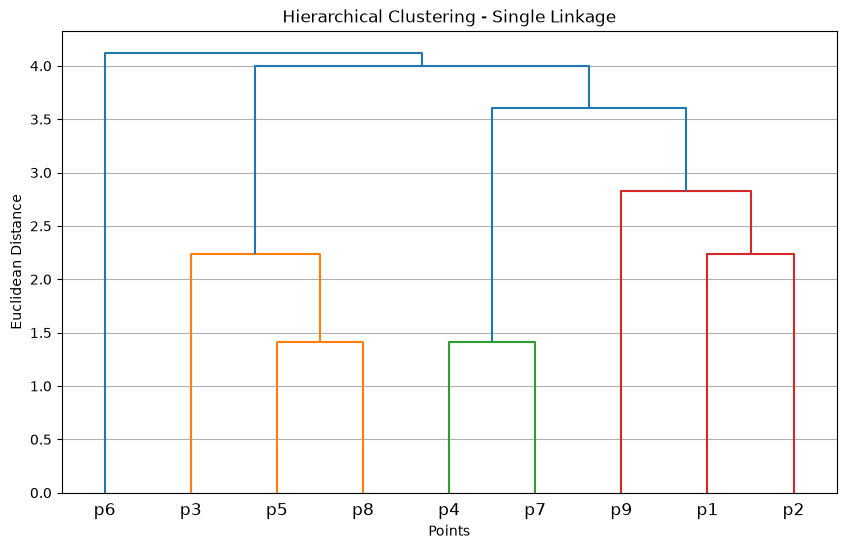

In [52]:
Z_single = linkage(
    X,
    method="single",
    metric="euclidean"
)

plt.figure(figsize=(10, 6))

dendrogram(
    Z_single,
    labels=df["Point"].tolist()
)

plt.title("Hierarchical Clustering - Single Linkage")
plt.xlabel("Points")
plt.ylabel("Euclidean Distance")

plt.grid(axis="y")

plt.show()

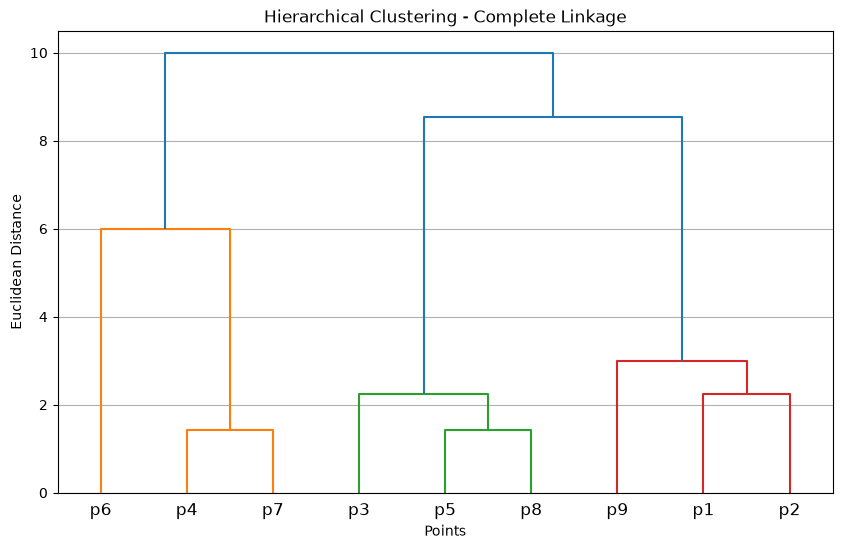

In [53]:
Z_complete = linkage(
    X,
    method="complete",
    metric="euclidean"
)

plt.figure(figsize=(10, 6))

dendrogram(
    Z_complete,
    labels=df["Point"].tolist()
)

plt.title("Hierarchical Clustering - Complete Linkage")
plt.xlabel("Points")
plt.ylabel("Euclidean Distance")

plt.grid(axis="y")

plt.show()

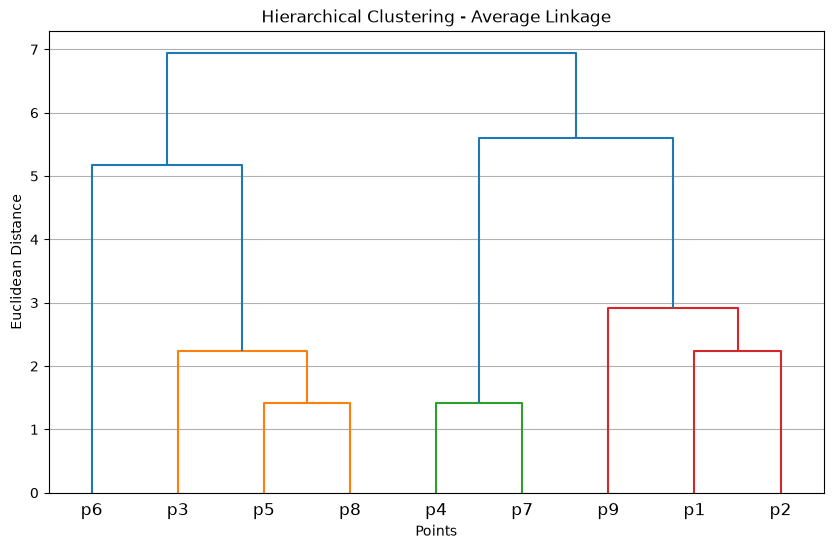

In [54]:
Z_average = linkage(
    X,
    method="average",
    metric="euclidean"
)

plt.figure(figsize=(10, 6))

dendrogram(
    Z_average,
    labels=df["Point"].tolist()
)

plt.title("Hierarchical Clustering - Average Linkage")
plt.xlabel("Points")
plt.ylabel("Euclidean Distance")

plt.grid(axis="y")

plt.show()

In [55]:
print("SINGLE LINKAGE")
display(single_history.round(3))

SINGLE LINKAGE


,Iteration,Cluster 1,Cluster 2,Distance
0,1,['p4'],['p7'],1.414
1,2,['p5'],['p8'],1.414
2,3,['p1'],['p2'],2.236
3,4,['p3'],"['p5', 'p8']",2.236
4,5,['p9'],"['p1', 'p2']",2.828
5,6,"['p4', 'p7']","['p9', 'p1', 'p2']",3.606
6,7,"['p3', 'p5', 'p8']","['p4', 'p7', 'p9', 'p1', 'p2']",4.000
7,8,['p6'],"['p3', 'p5', 'p8', 'p4', 'p7', 'p9', 'p1', 'p2']",4.123


In [56]:
print("COMPLETE LINKAGE")
display(complete_history.round(3))

COMPLETE LINKAGE


,Iteration,Cluster 1,Cluster 2,Distance
0,1,['p4'],['p7'],1.414
1,2,['p5'],['p8'],1.414
2,3,['p1'],['p2'],2.236
3,4,['p3'],"['p5', 'p8']",2.236
4,5,['p9'],"['p1', 'p2']",3.000
5,6,['p6'],"['p4', 'p7']",6.000
6,7,"['p3', 'p5', 'p8']","['p9', 'p1', 'p2']",8.544
7,8,"['p6', 'p4', 'p7']","['p3', 'p5', 'p8', 'p9', 'p1', 'p2']",10.000


In [57]:
print("AVERAGE LINKAGE")
display(average_history.round(3))

AVERAGE LINKAGE


,Iteration,Cluster 1,Cluster 2,Distance
0,1,['p4'],['p7'],1.414
1,2,['p5'],['p8'],1.414
2,3,['p1'],['p2'],2.236
3,4,['p3'],"['p5', 'p8']",2.236
4,5,['p9'],"['p1', 'p2']",2.914
5,6,['p6'],"['p3', 'p5', 'p8']",5.169
6,7,"['p4', 'p7']","['p9', 'p1', 'p2']",5.605
7,8,"['p6', 'p3', 'p5', 'p8']","['p4', 'p7', 'p9', 'p1', 'p2']",6.947


#### 4. Consider the above-mentioned data set in Q no 1 and apply the hierarchical data-clustering algorithm, to identify the clusters. Write a Python function (without using the `scikit-learn` library) to do the following: 
- Plot a scatter graph of given data points.
- Display the proximity matrix using Euclidean distance, Manhattan distance, and Minkowski distance.
- Plot the dendrogram for single, complete and average linkage methods.

In [58]:
df = pd.read_csv("rebounds.csv")
df.head()

,player,points,assists,rebounds
0,1,18.0,3.0,15
1,2,19.0,4.0,14
2,3,14.0,5.0,10
3,4,14.0,4.0,8
4,5,11.0,7.0,14


In [59]:
X = df.values.astype(float)
X

array([[ 1., 18.,  3., 15.],
       [ 2., 19.,  4., 14.],
       [ 3., 14.,  5., 10.],
       [ 4., 14.,  4.,  8.],
       [ 5., 11.,  7., 14.],
       [ 6., 20.,  8., 13.],
       [ 7., 28.,  7.,  9.],
       [ 8., 30.,  6.,  5.],
       [ 9., 31.,  9.,  4.],
       [10., 35., 12., 11.],
       [11., 33., 14.,  6.],
       [12., 25.,  9.,  5.],
       [13., 25.,  4.,  3.],
       [14., 27.,  3.,  8.],
       [15., 29.,  4., 12.],
       [16., 30., 12.,  7.],
       [17., 19., 15.,  6.],
       [18., 23., 11.,  5.]])

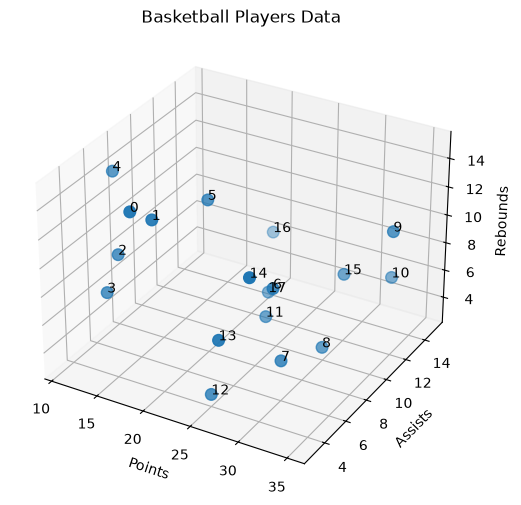

In [60]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    df["points"],
    df["assists"],
    df["rebounds"],
    s=70
)

for i in range(len(df)):

    ax.text(
        df.iloc[i]["points"],
        df.iloc[i]["assists"],
        df.iloc[i]["rebounds"],
        df.index[i]
    )

ax.set_xlabel("Points")
ax.set_ylabel("Assists")
ax.set_zlabel("Rebounds")

ax.set_title("Basketball Players Data")

plt.show()

In [61]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan_distance(a, b):
    return np.sum(np.abs(a - b))

def minkowski_distance(a, b, p=3):
    return (np.sum(np.abs(a - b) ** p)) ** (1 / p)

In [62]:
def proximity_matrix(X, distance="euclidean", p=3):
    n = len(X)
    matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            if distance == "euclidean":
                matrix[i, j] = euclidean_distance(
                    X[i], X[j]
                )

            elif distance == "manhattan":
                matrix[i, j] = manhattan_distance(
                    X[i], X[j]
                )

            elif distance == "minkowski":
                matrix[i, j] = minkowski_distance(
                    X[i], X[j], p
                )

    return matrix

In [63]:
euclidean_matrix = proximity_matrix(
    X,
    distance="euclidean"
)

euclidean_df = pd.DataFrame(
    euclidean_matrix,
    index=df.index,
    columns=df.index
)

euclidean_df.round(3)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,0.000,2.000,7.000,8.660,9.055,7.616,13.711,17.378,19.748,21.610,22.956,17.493,18.385,17.292,18.083,22.672,21.954,21.863
1,2.000,0.000,6.557,8.062,9.055,5.831,11.832,15.556,17.833,19.824,21.000,15.556,16.673,15.652,16.523,20.736,20.248,20.050
2,7.000,6.557,0.000,2.449,5.745,7.937,14.731,17.521,19.416,23.238,22.847,15.588,16.462,17.263,19.339,21.977,18.358,19.157
3,8.660,8.062,2.449,0.000,7.416,9.000,14.663,16.882,18.841,23.452,22.672,14.799,15.067,16.432,19.026,21.564,17.861,18.303
4,9.055,9.055,5.745,7.416,0.000,9.165,17.833,21.260,22.804,25.199,25.159,18.166,19.748,19.723,20.905,23.580,18.330,20.248
5,7.616,5.831,7.937,9.000,9.165,0.000,9.055,13.115,14.560,16.155,16.703,11.225,13.784,12.767,13.379,15.875,14.832,15.033
6,13.711,11.832,14.731,14.663,17.833,9.055,0.000,4.690,6.481,9.327,9.950,7.348,9.487,8.185,9.110,10.677,15.937,13.342
7,17.378,15.556,17.521,16.882,21.260,13.115,4.690,0.000,3.464,10.050,9.110,7.071,7.616,7.937,10.149,10.198,16.852,13.191
8,19.748,17.833,19.416,18.841,22.804,14.560,6.481,3.464,0.000,8.660,6.083,6.782,8.832,9.644,11.358,8.246,15.748,12.247
9,21.610,19.824,23.238,23.452,25.199,16.155,9.327,10.050,8.660,0.000,5.831,12.207,15.395,13.038,11.225,8.775,18.412,15.652


In [64]:
manhattan_matrix = proximity_matrix(
    X,
    distance="manhattan"
)

manhattan_df = pd.DataFrame(
    manhattan_matrix,
    index=df.index,
    columns=df.index
)

manhattan_df.round(3)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,0.0,4.0,13.0,15.0,16.0,14.0,26.0,32.0,38.0,39.0,45.0,34.0,32.0,29.0,29.0,44.0,38.0,40.0
1,4.0,0.0,11.0,13.0,14.0,10.0,22.0,28.0,34.0,35.0,41.0,30.0,28.0,27.0,25.0,40.0,34.0,36.0
2,13.0,11.0,0.0,4.0,11.0,15.0,21.0,27.0,33.0,36.0,40.0,29.0,29.0,28.0,30.0,39.0,33.0,35.0
3,15.0,13.0,4.0,0.0,13.0,17.0,21.0,25.0,31.0,38.0,38.0,27.0,25.0,24.0,30.0,37.0,31.0,33.0
4,16.0,14.0,11.0,13.0,0.0,12.0,24.0,32.0,36.0,37.0,43.0,32.0,36.0,35.0,33.0,42.0,36.0,38.0
5,14.0,10.0,15.0,17.0,12.0,0.0,14.0,22.0,24.0,25.0,31.0,20.0,26.0,25.0,23.0,30.0,26.0,26.0
6,26.0,22.0,21.0,21.0,24.0,14.0,0.0,8.0,12.0,17.0,19.0,14.0,18.0,13.0,15.0,18.0,30.0,24.0
7,32.0,28.0,27.0,25.0,32.0,22.0,8.0,0.0,6.0,19.0,15.0,12.0,14.0,15.0,17.0,16.0,30.0,22.0
8,38.0,34.0,33.0,31.0,36.0,24.0,12.0,6.0,0.0,15.0,11.0,10.0,16.0,19.0,21.0,14.0,28.0,20.0
9,39.0,35.0,36.0,38.0,37.0,25.0,17.0,19.0,15.0,0.0,10.0,21.0,29.0,24.0,20.0,15.0,31.0,27.0


In [65]:
minkowski_matrix = proximity_matrix(
    X,
    distance="minkowski",
    p=3
)

minkowski_df = pd.DataFrame(
    minkowski_matrix,
    index=df.index,
    columns=df.index
)

minkowski_df.round(3)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,0.000,1.587,5.896,7.577,7.786,6.431,11.437,14.578,16.206,18.600,18.600,14.244,15.605,14.841,16.009,18.512,18.714,18.710
1,1.587,0.000,5.759,7.041,8.272,5.066,10.020,13.169,14.730,17.266,17.083,12.745,14.224,13.494,14.744,17.020,17.345,17.360
2,5.896,5.759,0.000,2.154,4.747,6.672,14.123,16.320,17.554,21.507,20.136,13.102,13.882,15.246,17.226,18.817,15.785,16.442
3,7.577,7.041,2.154,0.000,6.471,7.447,14.093,16.128,17.355,21.556,20.173,12.589,12.976,14.733,16.833,18.505,15.412,15.664
4,7.786,8.272,4.747,6.471,0.000,9.012,17.152,19.675,20.856,24.159,22.714,15.638,16.648,17.219,19.007,20.534,14.834,16.772
5,6.431,5.066,6.672,7.447,9.012,0.000,8.330,11.518,12.781,15.199,14.229,9.488,11.528,10.338,11.505,13.162,12.637,13.189
6,11.437,10.020,14.123,14.093,17.152,8.330,0.000,4.198,5.518,7.953,8.238,6.073,7.862,7.423,8.277,9.546,13.139,11.657
7,14.578,13.169,16.320,16.128,19.675,11.518,4.198,0.000,3.107,8.267,8.277,6.000,6.431,6.672,8.858,9.029,14.078,11.365
8,16.206,14.730,17.554,17.355,20.856,12.781,5.518,3.107,0.000,7.577,5.301,6.249,7.405,7.769,9.513,7.356,13.507,10.772
9,18.600,17.266,21.507,21.556,24.159,15.199,7.953,8.267,7.577,0.000,5.217,10.775,12.705,11.003,9.488,7.399,16.620,13.494


In [66]:
from scipy.spatial.distance import pdist

def plot_dendrogram(X, labels, linkage_type):
    distances = pdist(
        X,
        metric="euclidean"
    )

    Z = linkage(
        distances,
        method=linkage_type
    )

    plt.figure(figsize=(12, 6))

    dendrogram(
        Z,
        labels=labels
    )

    plt.title(
        f"Hierarchical Clustering - "
        f"{linkage_type.capitalize()} Linkage"
    )

    plt.xlabel("Players")
    plt.ylabel("Euclidean Distance")

    plt.grid(axis="y")

    plt.show()

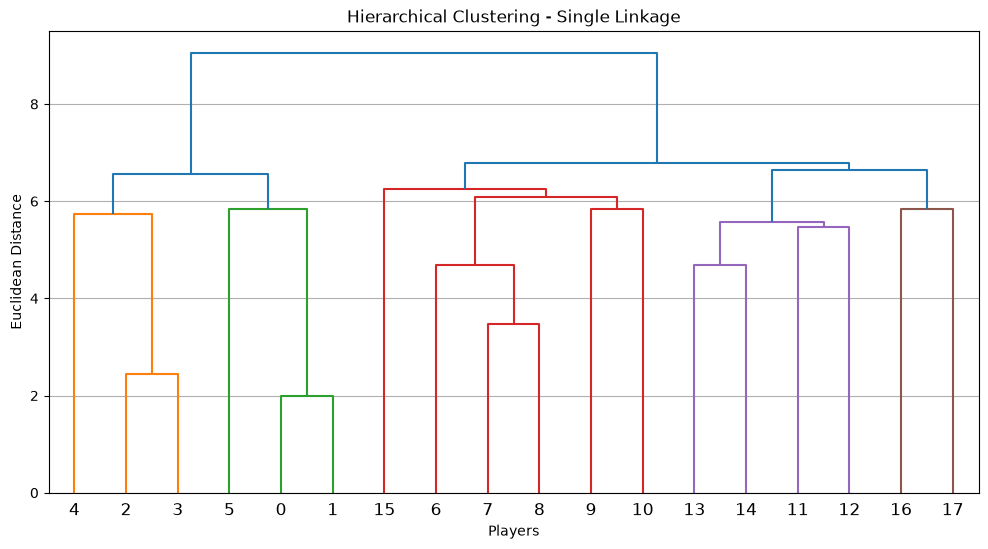

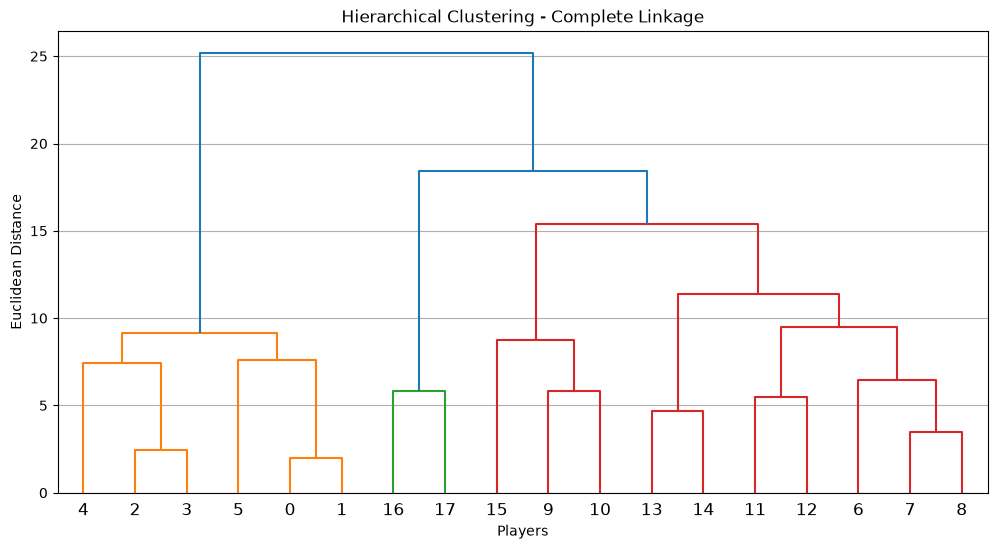

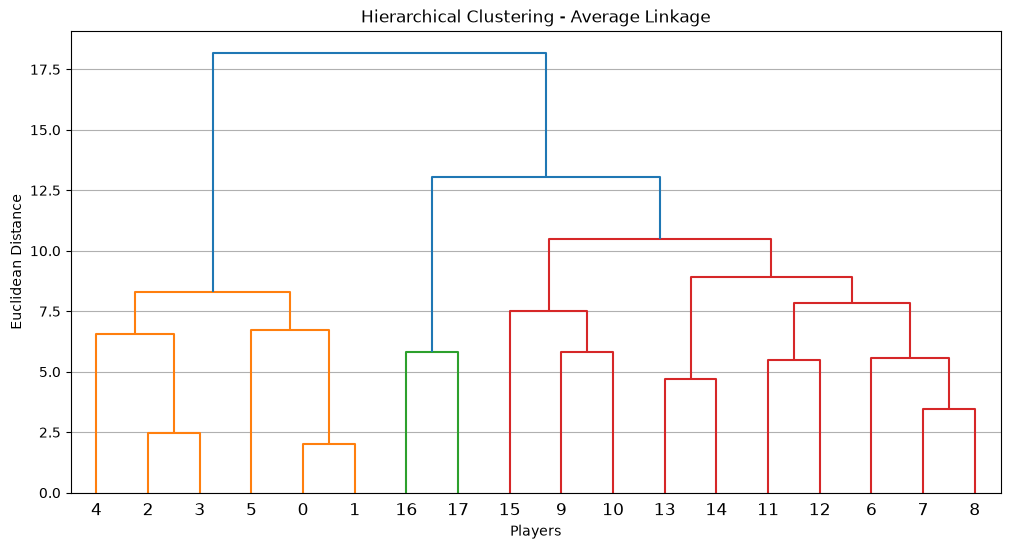

In [67]:
plot_dendrogram(
    X,
    df.index.tolist(),
    "single"
)

plot_dendrogram(
    X,
    df.index.tolist(),
    "complete"
)

plot_dendrogram(
    X,
    df.index.tolist(),
    "average"
)